# Assignment 07: Informed and Adversarial Search

Greedy best-first search, A*, minimax, alpha-beta pruning, move ordering, and cutoff search are implemented from scratch; no built-in search or game solvers are used.

In [1]:
import heapq
import random
import time

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

## Greedy Best-First Search and A*

The graph has 12 states with directed weighted edges, a start state `S`, a goal state `G`, and a heuristic $h(n)$. Greedy best-first expands the frontier node with the smallest $h(n)$ and ignores accumulated cost; A* expands the smallest

$$f(n) = g(n) + h(n),$$

where $g(n)$ is the cost from the start. $h$ is admissible (it never exceeds the true remaining cost).

In [2]:
EDGES = {
    "S": [("A", 1), ("B", 1)],
    "A": [("C", 1), ("G", 2)],
    "B": [("D", 1), ("E", 1)],
    "C": [("F", 1)],
    "F": [("G", 1)],
    "D": [("G", 10)],
    "E": [("H", 1)],
    "H": [("I", 1)],
    "I": [("J", 1)],
    "J": [("K", 1)],
    "K": [("G", 1)],
    "G": [],
}
H = {"S": 3, "A": 2, "B": 1, "C": 1, "D": 10, "E": 1, "F": 1,
     "G": 0, "H": 1, "I": 1, "J": 1, "K": 1}

print(len(EDGES), "states")

12 states


In [3]:
def greedy_best_first(start, goal, edges, h):
    frontier = [(h[start], 0, start, [start])]
    visited = set()
    expanded = 0
    while frontier:
        _, cost, node, path = heapq.heappop(frontier)
        if node in visited:
            continue
        visited.add(node)
        expanded += 1
        if node == goal:
            return path, cost, expanded
        for nb, w in edges[node]:
            if nb not in visited:
                heapq.heappush(frontier, (h[nb], cost + w, nb, path + [nb]))
    return None, None, expanded


def a_star(start, goal, edges, h):
    frontier = [(h[start], 0, start, [start])]
    best_g = {start: 0}
    expanded = 0
    while frontier:
        _, g, node, path = heapq.heappop(frontier)
        if g > best_g.get(node, float("inf")):
            continue
        expanded += 1
        if node == goal:
            return path, g, expanded
        for nb, w in edges[node]:
            ng = g + w
            if ng < best_g.get(nb, float("inf")):
                best_g[nb] = ng
                heapq.heappush(frontier, (ng + h[nb], ng, nb, path + [nb]))
    return None, None, expanded

In [4]:
for name, algo in [("Greedy best-first", greedy_best_first), ("A*", a_star)]:
    path, cost, expanded = algo("S", "G", EDGES, H)
    print(f"{name:17s} path: {' -> '.join(path)}")
    print(f"{'':17s} cost: {cost}   expanded nodes: {expanded}\n")

Greedy best-first path: S -> B -> E -> H -> I -> J -> K -> G
                  cost: 7   expanded nodes: 8

A*                path: S -> A -> G
                  cost: 3   expanded nodes: 6



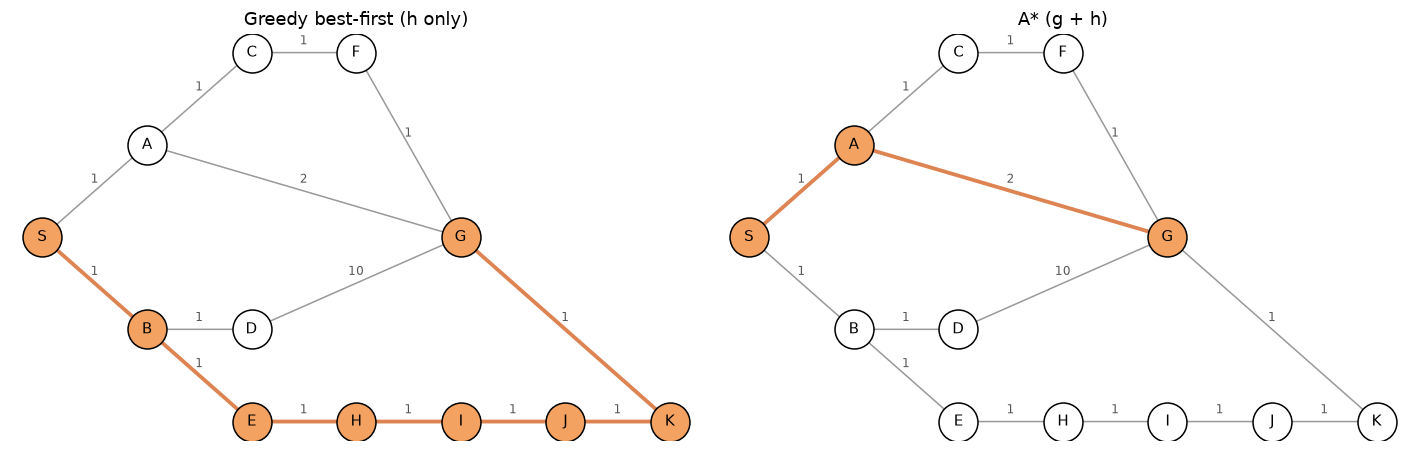

In [5]:
POS = {
    "S": (0, 3), "A": (1, 4), "B": (1, 2), "C": (2, 5), "F": (3, 5),
    "D": (2, 2), "E": (2, 1), "G": (4, 3), "H": (3, 1), "I": (4, 1),
    "J": (5, 1), "K": (6, 1),
}


def draw_graph(ax, path, title):
    for u, nbrs in EDGES.items():
        for v, w in nbrs:
            x1, y1 = POS[u]
            x2, y2 = POS[v]
            ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                        arrowprops=dict(arrowstyle="-|>", color="#999999", lw=1))
            ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.09, str(w),
                    color="#555555", fontsize=8, ha="center")
    for u, v in zip(path, path[1:]):
        x1, y1 = POS[u]
        x2, y2 = POS[v]
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="-|>", color="#dd8452", lw=2.5))
    for node, (x, y) in POS.items():
        color = "#f4a261" if node in path else "white"
        ax.scatter([x], [y], s=650, c=color, edgecolors="black", zorder=3)
        ax.text(x, y, node, ha="center", va="center", fontsize=10, zorder=4)
    ax.set_title(title)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
draw_graph(axes[0], greedy_best_first("S", "G", EDGES, H)[0], "Greedy best-first (h only)")
draw_graph(axes[1], a_star("S", "G", EDGES, H)[0], "A* (g + h)")
plt.tight_layout()
plt.show()

Greedy best-first commits to the neighbor with the smallest heuristic value, so it enters the long branch through `B` and reaches the goal at cost 7. A* adds the accumulated cost to the heuristic and therefore prefers `A`, whose estimate plus cost is lower, recovering the optimal path `S -> A -> G` at cost 3. The paths differ because $h$ alone estimates only the remaining cost, while $f$ also accounts for the cost already paid.

## Heuristic Effect in Grid A*

A $15 \times 15$ grid contains fixed obstacles and movement is four-directional with unit cost. A* is run with the Manhattan distance

$$h(n) = |x_n - x_g| + |y_n - y_g|$$

and again with $h(n) = 0$. Both are admissible, so both return a minimum-cost path; only the search effort differs.

In [6]:
N = 15
START, GOAL = (0, 0), (N - 1, N - 1)


def neighbors(r, c):
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        nr, nc = r + dr, c + dc
        if 0 <= nr < N and 0 <= nc < N:
            yield nr, nc


def make_grid(seed, density=0.28):
    rng = random.Random(seed)
    g = np.zeros((N, N), dtype=bool)
    for i in range(N):
        for j in range(N):
            g[i, j] = rng.random() < density
    g[START] = g[GOAL] = False
    return g


def reachable(g):
    seen = {START}
    stack = [START]
    while stack:
        cur = stack.pop()
        if cur == GOAL:
            return True
        for nb in neighbors(*cur):
            if nb not in seen and not g[nb]:
                seen.add(nb)
                stack.append(nb)
    return False


for seed in range(100):
    grid = make_grid(seed)
    if reachable(grid):
        print("obstacle seed:", seed)
        break

print("obstacle fraction:", round(grid.mean(), 3))

obstacle seed: 0
obstacle fraction: 0.236


In [7]:
def astar_grid(g, start, goal, hfun):
    frontier = [(hfun(start, goal), 0, start)]
    best_g = {start: 0}
    parent = {start: None}
    closed = set()
    while frontier:
        _, gcost, cur = heapq.heappop(frontier)
        if cur in closed:
            continue
        closed.add(cur)
        if cur == goal:
            break
        for nb in neighbors(*cur):
            if g[nb] or nb in closed:
                continue
            ng = gcost + 1
            if ng < best_g.get(nb, float("inf")):
                best_g[nb] = ng
                parent[nb] = cur
                heapq.heappush(frontier, (ng + hfun(nb, goal), ng, nb))
    path = []
    cur = goal
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    path.reverse()
    return path, closed


def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


path_h, closed_h = astar_grid(grid, START, GOAL, manhattan)
path_0, closed_0 = astar_grid(grid, START, GOAL, lambda a, b: 0)

print(f"Manhattan : path cost {len(path_h) - 1}, expanded {len(closed_h)}")
print(f"h = 0     : path cost {len(path_0) - 1}, expanded {len(closed_0)}")

Manhattan : path cost 28, expanded 80
h = 0     : path cost 28, expanded 170


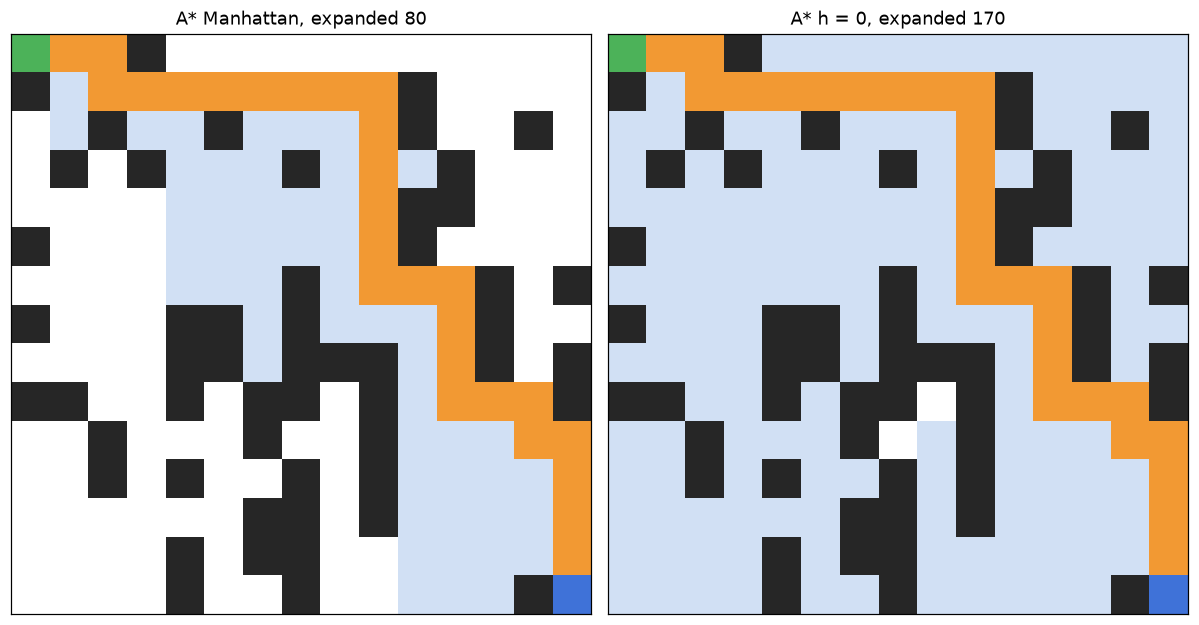

In [8]:
def draw_grid(ax, grid, path, closed, title):
    img = np.ones((N, N, 3))
    img[grid] = (0.15, 0.15, 0.15)
    for r, c in closed:
        img[r, c] = (0.82, 0.88, 0.96)
    for r, c in path:
        img[r, c] = (0.95, 0.60, 0.20)
    img[START] = (0.30, 0.70, 0.35)
    img[GOAL] = (0.25, 0.45, 0.85)
    ax.imshow(img, origin="upper")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
draw_grid(axes[0], grid, path_h, closed_h, f"A* Manhattan, expanded {len(closed_h)}")
draw_grid(axes[1], grid, path_0, closed_0, f"A* h = 0, expanded {len(closed_0)}")
plt.tight_layout()
plt.show()

Both runs return the same optimal cost, but $h=0$ reduces A* to Dijkstra's algorithm and expands far more nodes because it has no directional guidance. Manhattan distance underestimates the true remaining cost while pointing the search toward the goal, so A* expands substantially fewer nodes. The heuristic does not change the optimal path cost on a unit-cost grid; it changes how much of the state space must be explored to guarantee optimality.

## Minimax for Tic-Tac-Toe

The game is defined by `player(s)`, `actions(s)`, `result(s, a)`, `terminal(s)`, and the utility

$$U(s) = \begin{cases} +1 & \text{MAX (X) wins} \\ 0 & \text{draw} \\ -1 & \text{MIN (O) wins} \end{cases}$$

Minimax expands the full game tree, with MAX selecting the maximum child value and MIN the minimum.

In [9]:
WIN_LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6),
             (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6)]
CORNERS = {0, 2, 6, 8}


def winner(state):
    for a, b, c in WIN_LINES:
        if state[a] != "." and state[a] == state[b] == state[c]:
            return state[a]
    return None


def terminal(state):
    return winner(state) is not None or "." not in state


def utility(state):
    w = winner(state)
    return 1 if w == "X" else (-1 if w == "O" else 0)


def player(state):
    return "X" if state.count("X") == state.count("O") else "O"


def actions(state):
    return [i for i, c in enumerate(state) if c == "."]


def result(state, a, p):
    s = list(state)
    s[a] = p
    return tuple(s)


def show(state):
    return "\n".join(" ".join(state[i:i + 3]) for i in range(0, 9, 3))

In [10]:
def minimax(state, is_max, nodes):
    nodes[0] += 1
    if terminal(state):
        return utility(state), None
    if is_max:
        best_val, best_move = -2, None
        for a in actions(state):
            val, _ = minimax(result(state, a, "X"), False, nodes)
            if val > best_val:
                best_val, best_move = val, a
        return best_val, best_move
    best_val, best_move = 2, None
    for a in actions(state):
        val, _ = minimax(result(state, a, "O"), True, nodes)
        if val < best_val:
            best_val, best_move = val, a
    return best_val, best_move

In [11]:
STATES = [
    tuple("........."),
    tuple("X...O...."),
    tuple("XO..X...O"),
]

for state in STATES:
    nodes = [0]
    t0 = time.time()
    val, move = minimax(state, player(state) == "X", nodes)
    dt = time.time() - t0
    print(show(state))
    print(f"player {player(state)}: optimal move {move}, minimax value {val}, "
          f"evaluated nodes {nodes[0]} ({dt:.3f}s)\n")

. . .
. . .
. . .
player X: optimal move 0, minimax value 0, evaluated nodes 549946 (0.496s)

X . .
. O .
. . .
player X: optimal move 1, minimax value 0, evaluated nodes 7332 (0.007s)

X O .
. X .
. . O
player X: optimal move 3, minimax value 1, evaluated nodes 238 (0.000s)



The empty board has value 0 under optimal play, so every first move is equally good for MAX and minimax returns the first maximizing move it encounters. The second state is also a draw, and the third is a forced win after move 3, where X creates two simultaneous threats that O cannot block. The empty board evaluates the largest tree because it has the most remaining plies.

## Alpha-Beta Pruning

Alpha-beta carries the best value guaranteed to MAX ($\alpha$) and the best value guaranteed to MIN ($\beta$). A branch is cut when $\beta \le \alpha$, because the opponent would never allow that line. Move ordering is identical to minimax so the returned decision can be compared directly.

In [12]:
def alphabeta(state, is_max, alpha, beta, nodes, prunes):
    nodes[0] += 1
    if terminal(state):
        return utility(state), None
    if is_max:
        best_val, best_move = -2, None
        for a in actions(state):
            val, _ = alphabeta(result(state, a, "X"), False, alpha, beta, nodes, prunes)
            if val > best_val:
                best_val, best_move = val, a
            alpha = max(alpha, best_val)
            if beta <= alpha:
                prunes[0] += 1
                break
        return best_val, best_move
    best_val, best_move = 2, None
    for a in actions(state):
        val, _ = alphabeta(result(state, a, "O"), True, alpha, beta, nodes, prunes)
        if val < best_val:
            best_val, best_move = val, a
        beta = min(beta, best_val)
        if beta <= alpha:
            prunes[0] += 1
            break
    return best_val, best_move

state 1: minimax    move 0, value 0, nodes 549946
         alpha-beta move 0, value 0, nodes 18297, pruned 8180
state 2: minimax    move 1, value 0, nodes 7332
         alpha-beta move 1, value 0, nodes 844, pruned 344
state 3: minimax    move 3, value 1, nodes 238
         alpha-beta move 3, value 1, nodes 93, pruned 28


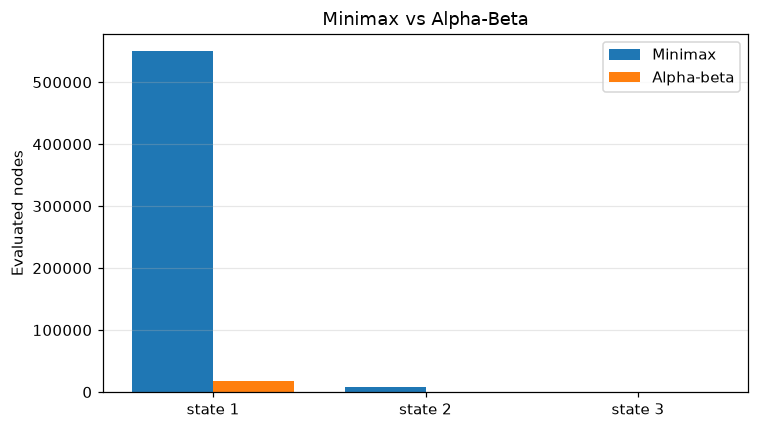

In [13]:
mm_nodes, ab_nodes = [], []
for i, state in enumerate(STATES, 1):
    is_max = player(state) == "X"
    n1 = [0]
    val_m, move_m = minimax(state, is_max, n1)
    n2, pr = [0], [0]
    val_a, move_a = alphabeta(state, is_max, -2, 2, n2, pr)
    mm_nodes.append(n1[0])
    ab_nodes.append(n2[0])
    print(f"state {i}: minimax    move {move_m}, value {val_m}, nodes {n1[0]}")
    print(f"         alpha-beta move {move_a}, value {val_a}, nodes {n2[0]}, pruned {pr[0]}")

x = np.arange(len(STATES))
width = 0.38
plt.figure(figsize=(7, 4))
plt.bar(x - width / 2, mm_nodes, width, label="Minimax")
plt.bar(x + width / 2, ab_nodes, width, label="Alpha-beta")
plt.xticks(x, [f"state {i + 1}" for i in range(len(STATES))])
plt.ylabel("Evaluated nodes")
plt.title("Minimax vs Alpha-Beta")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Alpha-beta returns the same move and utility as minimax on all three states, confirming that pruning removes only branches that cannot affect the decision. It evaluates substantially fewer nodes, with the largest reduction on the empty board where the tree is deepest. The saving depends on move ordering: a better order tightens the bounds earlier and prunes more.

## Move Ordering and Cutoff Search

Three orderings are compared: random, promising moves first, and promising moves last. A move is promising if it wins immediately, blocks an opponent win, or occupies the center or a corner. A depth-limited variant replaces utility at the cutoff with

$$\text{eval}(s) = \sum_i w_i f_i(s), \qquad w = (0.5, 0.3, 0.2),$$

using features $f_1$ = immediate two-in-a-row threats (X minus O), $f_2$ = center control, and $f_3$ = normalized corner control.

In [14]:
def move_priority(state, a):
    p = player(state)
    opp = "O" if p == "X" else "X"
    if winner(result(state, a, p)) == p:
        return 4
    if winner(result(state, a, opp)) == opp:
        return 3
    if a == 4:
        return 2
    if a in CORNERS:
        return 1
    return 0


def order_first(state, acts):
    return sorted(acts, key=lambda a: -move_priority(state, a))


def order_last(state, acts):
    return sorted(acts, key=lambda a: move_priority(state, a))


_rng = random.Random(0)


def order_random(state, acts):
    out = list(acts)
    _rng.shuffle(out)
    return out

In [15]:
def alphabeta_ordered(state, is_max, alpha, beta, nodes, order_fn):
    nodes[0] += 1
    if terminal(state):
        return utility(state), None
    acts = order_fn(state, actions(state))
    if is_max:
        best_val, best_move = -2, None
        for a in acts:
            val, _ = alphabeta_ordered(result(state, a, "X"), False, alpha, beta, nodes, order_fn)
            if val > best_val:
                best_val, best_move = val, a
            alpha = max(alpha, best_val)
            if beta <= alpha:
                break
        return best_val, best_move
    best_val, best_move = 2, None
    for a in acts:
        val, _ = alphabeta_ordered(result(state, a, "O"), True, alpha, beta, nodes, order_fn)
        if val < best_val:
            best_val, best_move = val, a
        beta = min(beta, best_val)
        if beta <= alpha:
            break
    return best_val, best_move

state 1  promising first: move 4, value 0, nodes 2096


state 1  promising last : move 1, value 0, nodes 93350


state 1  random         : move 7, value 0, nodes 15795
state 2  promising first: move 2, value 0, nodes 228
state 2  promising last : move 1, value 0, nodes 2909
state 2  random         : move 1, value 0, nodes 924
state 3  promising first: move 6, value 1, nodes 60
state 3  promising last : move 3, value 1, nodes 73
state 3  random         : move 3, value 1, nodes 112


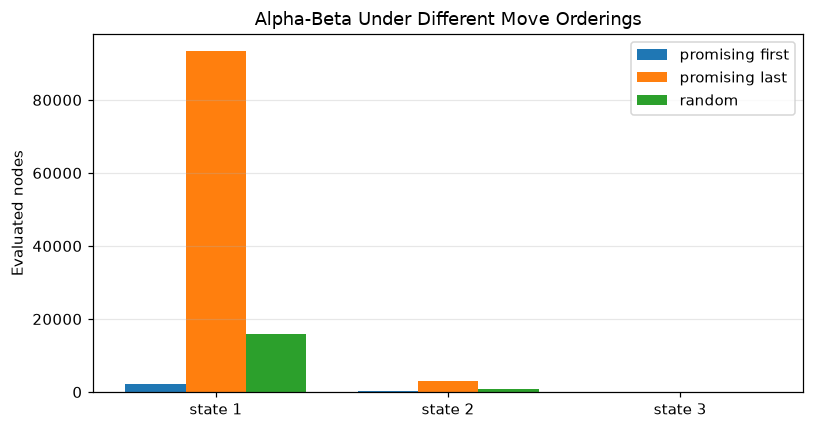

In [16]:
orderings = [("promising first", order_first), ("promising last", order_last), ("random", order_random)]
results = {name: [] for name, _ in orderings}

for i, state in enumerate(STATES, 1):
    is_max = player(state) == "X"
    for name, fn in orderings:
        nodes = [0]
        val, move = alphabeta_ordered(state, is_max, -2, 2, nodes, fn)
        results[name].append(nodes[0])
        print(f"state {i}  {name:15s}: move {move}, value {val}, nodes {nodes[0]}")

x = np.arange(len(STATES))
width = 0.26
plt.figure(figsize=(7.5, 4))
for i, (name, _) in enumerate(orderings):
    plt.bar(x + (i - 1) * width, results[name], width, label=name)
plt.xticks(x, [f"state {i + 1}" for i in range(len(STATES))])
plt.ylabel("Evaluated nodes")
plt.title("Alpha-Beta Under Different Move Orderings")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
def eval_state(state):
    w = winner(state)
    if w == "X":
        return 1.0
    if w == "O":
        return -1.0
    threats = 0
    for a, b, c in WIN_LINES:
        line = [state[a], state[b], state[c]]
        if line.count("X") == 2 and "O" not in line:
            threats += 1
        if line.count("O") == 2 and "X" not in line:
            threats -= 1
    center = 1.0 if state[4] == "X" else (-1.0 if state[4] == "O" else 0.0)
    corners = sum(1 for i in CORNERS if state[i] == "X") - sum(1 for i in CORNERS if state[i] == "O")
    raw = 0.5 * threats + 0.3 * center + 0.2 * (corners / 4.0)
    return max(-1.0, min(1.0, raw))


def alphabeta_cutoff(state, is_max, alpha, beta, depth, max_depth, nodes):
    nodes[0] += 1
    if terminal(state):
        return utility(state), None
    if depth == max_depth:
        return eval_state(state), None
    acts = order_first(state, actions(state))
    if is_max:
        best_val, best_move = -2.0, None
        for a in acts:
            val, _ = alphabeta_cutoff(result(state, a, "X"), False, alpha, beta, depth + 1, max_depth, nodes)
            if val > best_val:
                best_val, best_move = val, a
            alpha = max(alpha, best_val)
            if beta <= alpha:
                break
        return best_val, best_move
    best_val, best_move = 2.0, None
    for a in acts:
        val, _ = alphabeta_cutoff(result(state, a, "O"), True, alpha, beta, depth + 1, max_depth, nodes)
        if val < best_val:
            best_val, best_move = val, a
        beta = min(beta, best_val)
        if beta <= alpha:
            break
    return best_val, best_move


print("cutoff search on the empty board (X to move)")
for d in [1, 2, 3, 4, 5, 6, 9]:
    nodes = [0]
    val, move = alphabeta_cutoff(tuple("........."), True, -2, 2, 0, d, nodes)
    print(f"depth {d}: move {move}, eval {val:+.3f}, nodes {nodes[0]}")

cutoff search on the empty board (X to move)
depth 1: move 4, eval +0.300, nodes 10
depth 2: move 4, eval +0.250, nodes 26
depth 3: move 4, eval +0.800, nodes 97
depth 4: move 4, eval +0.200, nodes 267
depth 5: move 4, eval +0.800, nodes 671
depth 6: move 4, eval +0.250, nodes 1163
depth 9: move 4, eval +0.000, nodes 2096


Promising-first ordering explores far fewer nodes than promising-last, because strong moves are examined early, the bounds tighten quickly, and later siblings are pruned. Random ordering lies between the two. Cutoff depth trades effort for accuracy: shallow cutoffs evaluate fewer nodes but return coarse, parity-sensitive estimates, while deeper cutoffs approach the true game value. Evaluation quality matters because a weak $eval$ can select an inferior move even with a deep search, so features and weights should reflect the structure of the game.